# 09. Готовая система на любом MP4


In [ ]:
import sys, os, subprocess, importlib.util
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
RUN_ID = 'blue_aug_20261112_v2'
BUNDLE = PROJECT / 'notebooks_colab_full'
assert (BUNDLE / 'tracking_lab.py').is_file(), BUNDLE
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
    'matplotlib':'matplotlib', 'tqdm':'tqdm', 'trackeval':'trackeval==1.3.0',
    'cryptography':'cryptography', 'imageio':'imageio', 'imageio_ffmpeg':'imageio-ffmpeg'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Совместимую пару torch/torchvision предоставляет Colab; автоматически её не заменяем.
sys.path.insert(0, str(BUNDLE))
import tracking_lab as tl
assert Path(tl.__file__).resolve() == (BUNDLE / 'tracking_lab.py').resolve(), 'Перезапустите runtime: загружен старый модуль'
assert tl.SCHEMA == 4, 'Перезапустите runtime после обновления исходного кода'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video, HTML, Image
lab = tl.Lab(PROJECT, RUN_ID)
torch.hub.set_dir(str(PROJECT / 'pretrained_cache'))
display(pd.Series(lab.environment(), name='Среда'))
print('Запуск:', RUN_ID, '| Результаты:', lab.root)

Mounted at /content/drive


,Среда
python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda
gpu,NVIDIA L4


Запуск: blue_aug_20261112_v2 | Результаты: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2


Интеграция проверенной Spatial ReID. Дополнительный код встроен в ноутбук. Обучающие модули и checkpoint не заменяются.

In [ ]:

from scipy.optimize import linear_sum_assignment


class SpatialReIDTracker:
    def __init__(self, max_age_seconds=3., min_hits=2, reid_gate=.45, appearance_weight=.25,
                 low_score=.1, high_score=.35, bank_score=.7, bank_margin=.08, bank_size=20,
                 iou_gate=.3):
        self.cfg = dict(max_age_seconds=max_age_seconds, min_hits=min_hits, reid_gate=reid_gate,
                        appearance_weight=appearance_weight, low_score=low_score, high_score=high_score,
                        bank_score=bank_score, bank_margin=bank_margin, bank_size=bank_size,
                        iou_gate=iou_gate)
        self.tracks, self.next_id = {}, 1

    def update(self, boxes, features, scores=None, dt=.2):
        boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
        features = np.asarray(features, dtype=float)
        features = features.reshape(len(boxes), -1) if len(boxes) else np.empty((0, 256))
        scores = np.ones(len(boxes)) if scores is None else np.asarray(scores, dtype=float)
        if not np.isfinite(dt) or dt <= 0:
            raise ValueError('Invalid time step')
        if len(features):
            norms = np.linalg.norm(features, axis=1, keepdims=True)
            if (norms < 1e-8).any() or not np.isfinite(features).all():
                raise ValueError('Invalid appearance features')
            features = features/norms
        if not np.isfinite(boxes).all() or not np.isfinite(scores).all():
            raise ValueError('Invalid detections')
        for key in list(self.tracks):
            self.tracks[key]['age'] += dt
            if self.tracks[key]['age'] > self.cfg['max_age_seconds']:
                del self.tracks[key]
        high = np.flatnonzero(scores >= self.cfg['high_score']).tolist()
        low = np.flatnonzero((scores >= self.cfg['low_score']) & (scores < self.cfg['high_score'])).tolist()
        matched_tracks, matched_boxes = set(), set()
        for indices, appearance in ((high, True), (low, False)):
            ids = [key for key in self.tracks if key not in matched_tracks]
            if not ids or not indices:
                continue
            overlaps = tl.iou_array([self.tracks[key]['bbox'] for key in ids], boxes[indices])
            distances = np.zeros_like(overlaps)
            if appearance and self.cfg['appearance_weight'] > 0:
                for i, key in enumerate(ids):
                    bank = np.asarray(self.tracks[key]['bank'])
                    distances[i] = np.median(1-bank@features[indices].T, axis=0)
                distances = np.clip(distances/2, 0, 1)
            weight = self.cfg['appearance_weight'] if appearance else 0.
            costs = weight*distances + (1-weight)*(1-overlaps)
            costs[overlaps < self.cfg['iou_gate']] = 1e6
            rr, cc = linear_sum_assignment(costs)
            for i, j in zip(rr, cc):
                if costs[i, j] >= 1e5:
                    continue
                key, index = ids[i], indices[j]
                tr = self.tracks[key]
                alternatives = np.r_[np.delete(costs[i], j), np.delete(costs[:, j], i)]
                margin = (float(alternatives.min()) if len(alternatives) else 1e6)-costs[i, j]
                # Update appearance only on an unambiguous, confident observation.
                if (appearance and scores[index] >= self.cfg['bank_score']
                        and margin >= self.cfg['bank_margin'] and costs[i, j] < .4):
                    tr['bank'].append(features[index].copy())
                tr.update(bbox=boxes[index].copy(), score=float(scores[index]), age=0., hits=tr['hits']+1)
                matched_tracks.add(key)
                matched_boxes.add(index)
        for index in high:
            if index in matched_boxes:
                continue
            self.tracks[self.next_id] = dict(bbox=boxes[index].copy(), score=float(scores[index]), age=0.,
                hits=1, bank=deque([features[index].copy()], maxlen=self.cfg['bank_size']))
            self.next_id += 1
        return [dict(track_id=key, bbox=tr['bbox'].tolist(), score=tr['score'])
                for key, tr in self.tracks.items() if tr['age'] == 0 and tr['hits'] >= self.cfg['min_hits']]


def validate_repaired_association(lab):
    variant = tl.load_json(lab.path('configs/selected_variant.json'))['variant']
    rows = tl.load_json(lab.path(f'artifacts/{variant}_tracker_search.json'))
    best = max(rows, key=lambda row: row['score'])
    candidate = int(best['candidate'])
    label = (f"checkpoint_search_{best['detector_checkpoint']}_{candidate % 3}"
             if 'detector_checkpoint' in best else f'tracker_search_{candidate}')
    folder = lab.path(f'artifacts/{label}/{variant}')
    weights, loaded, sources = tl.weight_hashes(lab, variant), {}, {}
    sequences = list(tl.group_sequences(lab.records('val')).items())[:lab.cfg['tracker_val_videos']]
    for video, seq in sequences:
        limit = lab.cfg['tracker_val_frames']
        records = seq if len(seq) <= limit else seq[(len(seq)-limit)//2:][:limit]
        path = folder/'clean'/f'{Path(video).stem}.json'
        saved = tl.load_json(path)
        sources[str(path)] = tl.file_hash(path)
        gt = tl.evaluation_records(lab, records, 'clean')
        if (saved['data_contract'] != tl.digest(records)
                or saved['exact_grid'] != [r['frame_idx'] for r in records]
                or saved['evaluation_gt_contract'] != tl.digest(gt)):
            raise ValueError(f'Changed validation contract: {video}')
        key = tl.inference_contract(lab, records, 'clean', weights)
        items = []
        for index, record in enumerate(tl.tqdm(records, desc=f'Чтение кэша {video}')):
            path = lab.path(f'artifacts/inference_cache/{key}/{index:07d}.json')
            item = tl.load_json(path)
            if (item['contract'] != tl.digest(dict(contract=key, record=record, index=index))
                    or item['frame_idx'] != record['frame_idx']):
                raise ValueError(f'Changed inference cache: {path}')
            items.append(item)
        loaded[video] = (records, gt, saved['records'], items)
    metrics = tl.tracking_metric_objects()
    summary, video_rows, configs = [], [], {}
    # Small predefined comparison. No development/final records are read here.
    for name, weight in [('Исходный', None), ('IoU', 0.), ('Spatial ReID 0.25', .25), ('Spatial ReID 0.5', .5)]:
        raw = {}
        cfg = dict(best['config'])
        if weight is not None:
            cfg.update(appearance_weight=weight, iou_gate=.3)
            configs[name] = cfg
        print('Проверка:', name)
        for video, (records, gt, original, items) in loaded.items():
            if weight is None:
                predictions = original
            else:
                tracker, predictions, previous = SpatialReIDTracker(**cfg), [], None
                for record, reference, item in zip(records, original, items):
                    dt = 1/record['fps'] if previous is None else record['time']-previous
                    previous = record['time']
                    tracks = tracker.update(item['boxes'], item['features'], item['scores'], dt)
                    predictions.append(dict(reference, tracks=tracks))
            data, _ = tl.metric_data(gt, predictions, lab.cfg['score_threshold'])
            raw[video] = {m.get_name(): m.eval_sequence(data) for m in metrics}
            video_rows.append(dict(method=name, video=video, **tl.metric_values(raw[video])))
        combined = {m.get_name(): m.combine_sequences({v: r[m.get_name()] for v, r in raw.items()})
                    for m in metrics}
        summary.append(dict(method=name, **tl.metric_values(combined)))
        display(pd.DataFrame([summary[-1]])[['method', 'HOTA', 'DetA', 'AssA', 'IDF1', 'MOTA', 'IDSW', 'Frag']])
    table = pd.DataFrame(summary)
    expected = pd.read_csv(folder/'aggregate.csv').query("scenario == 'clean'").iloc[0]
    if any(abs(float(table.iloc[0][k])-float(expected[k])) > 1e-6 for k in ('HOTA', 'IDF1', 'MOTA')):
        raise ValueError('Original tracking metrics did not reproduce')
    # Independent IoU implementation must reproduce the completed diagnostic.
    previous = pd.read_csv(lab.path('artifacts/cached_tracker_diagnostics/comparison.csv')).iloc[1]
    if any(abs(float(table.iloc[1][k])-float(previous[k])) > 1e-6 for k in ('HOTA', 'IDF1', 'MOTA')):
        raise ValueError('IoU control did not reproduce')
    winner = max((row for row in summary if row['method'] != 'Исходный'),
                 key=lambda row: (row['HOTA'], row['IDF1']))
    out = lab.path('artifacts/association_repair')
    out.mkdir(parents=True, exist_ok=True)
    table.to_csv(out/'validation.csv', index=False)
    pd.DataFrame(video_rows).to_csv(out/'validation_per_video.csv', index=False)
    (out/'candidate_source.py').write_text(REPAIRED_ASSOCIATION_SOURCE, encoding='utf-8')
    tl.save_json(out/'candidate.json', dict(variant=variant, method=winner['method'],
        tracker=configs[winner['method']], validation_metrics=winner,
        selection_rule='Maximum clean validation HOTA; tie by IDF1; no development/final feedback',
        weights=weights, sources=sources, source_sha256=tl.file_hash(out/'candidate_source.py'),
        context=lab.context(), activated=False))
    display(table[['method', 'HOTA', 'DetA', 'AssA', 'IDF1', 'MOTA', 'IDSW', 'Frag']])
    display(pd.DataFrame(video_rows))
    print('Кандидат для проверки на development:', winner['method'])
    print('Кандидат сохранён отдельно. Рабочая система, веса и прежние настройки не изменены.')
    return table


In [ ]:

import ast
import hashlib
import importlib.util
import inspect
import json
import shutil
import sys
import time
import zipfile


ACTIVE_ASSOCIATION_SHA256 = hashlib.sha256(REPAIRED_ASSOCIATION_SOURCE.encode('utf-8')).hexdigest()


def checked_repaired_candidate(lab):
    candidate = tl.load_json(lab.path('artifacts/association_repair/candidate.json'))
    source = lab.path('artifacts/association_repair/candidate_source.py')
    if (candidate['source_sha256'] != ACTIVE_ASSOCIATION_SHA256
            or tl.file_hash(source) != ACTIVE_ASSOCIATION_SHA256):
        raise ValueError('Код ассоциации отличается от проверенного кандидата')
    if candidate['context'] != lab.context():
        raise ValueError('Изменились данные конфигурации или среда кандидата')
    selected = tl.load_json(lab.path('configs/selected_variant.json'))['variant']
    if selected != candidate['variant'] or candidate['weights'] != tl.weight_hashes(lab, selected):
        raise ValueError('Изменились выбранный вариант или его веса')
    development = tl.load_json(lab.path('artifacts/association_repair/development_check.json'))
    if (not development.get('complete') or development['candidate_sha256'] != ACTIVE_ASSOCIATION_SHA256
            or development['variant'] != selected or development['tracker'] != candidate['tracker']):
        raise ValueError('Не завершена чистая development-проверка этого кандидата')
    records = lab.records('dev')
    original_tracker = tl.load_json(lab.path(f'configs/{selected}_tracker.json'))
    reference_contract = tl.digest(dict(context=lab.context(), records=records,
        pixels=lab.input_contract(records), weights=candidate['weights'], tracker=original_tracker, scenario='clean'))
    if development['reference_contract'] != reference_contract:
        raise ValueError('Development-проверка относится к другим данным или настройкам')
    comparison = pd.read_csv(lab.path('artifacts/association_repair/development.csv'))
    if (len(comparison) != 2 or comparison.iloc[0]['method'] != 'Исходный'
            or comparison.iloc[1]['method'] != candidate['method']
            or not np.isfinite(comparison[['HOTA', 'IDF1']].to_numpy()).all()
            or any(comparison.iloc[1][k] < comparison.iloc[0][k] for k in ('HOTA', 'IDF1'))):
        raise ValueError('Нет подтверждённого общего улучшения HOTA/IDF1 на development')
    return candidate


def install_repaired_evaluation(lab):
    candidate = checked_repaired_candidate(lab)
    # Changing this class does not alter training losses, source hashes or checkpoints.
    # Cached detections/features are independent of association; metrics have new labels.
    tl.TemporalTracker = SpatialReIDTracker
    for variant in tl.VARIANTS:
        path = lab.path(f'configs/repaired_{variant}_tracker.json')
        if path.exists() and tl.load_json(path) != candidate['tracker']:
            raise ValueError(f'Настройки исправленного трекера изменились: {path}')
        tl.save_json(path, candidate['tracker'])
    tl.build_report = build_repaired_report
    tl.freeze_release = freeze_repaired_release
    print('Подключена Spatial ReID; одинаковые зафиксированные настройки для трёх вариантов весов.')
    print('Основные Python-файлы и checkpoint не изменены.')
    return candidate


def build_repaired_report(lab):
    tables, coverage = [], []
    for variant in tl.VARIANTS:
        full = phase_complete(lab, variant, 'full_clean')
        suite = phase_complete(lab, variant, 'development')
        coverage.append(dict(variant=variant, full_clean=full, development_suite=suite))
        if suite:
            table = pd.read_csv(phase_spec(lab, variant, 'development')['out']/'aggregate.csv')
            tables.append(table.assign(association='Spatial ReID'))
    table = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
    table.to_csv(lab.path('reports/repaired_development_comparison.csv'), index=False)
    state = pd.DataFrame(coverage)
    state.to_csv(lab.path('reports/repaired_development_coverage.csv'), index=False)
    complete = bool(state.full_clean.all() and state.development_suite.all())
    text = 'Полное сравнение завершено.' if complete else 'Часть проверок ожидает продолжения; полного сравнения пока нет.'
    report = lab.path('reports/repaired_report.html')
    report.write_text('<meta charset="utf-8"><h1>Blue Team: исправленная ассоциация</h1>'
        + '<p>'+text+'</p>'+state.to_html(index=False)+table.to_html(index=False)
        + '<p>Метрики 0–1. Development не является независимым final. '
          'Вариант весов выбран ранее на validation; параметры ассоциации зафиксированы до development. '
          'При использовании кэша FPS включает сохранённые времена инференса, а не новый замер GPU.</p>',
        encoding='utf-8')
    return table, report


def render_frozen_tracking_source():
    # Export the exact tested class with only its name/global IoU reference adapted.
    class_tree = ast.parse(REPAIRED_ASSOCIATION_SOURCE)
    node = next(n for n in class_tree.body if isinstance(n, ast.ClassDef) and n.name == 'SpatialReIDTracker')
    node.name = 'TemporalTracker'

    class AdaptIoU(ast.NodeTransformer):
        def visit_Attribute(self, value):
            self.generic_visit(value)
            if isinstance(value.value, ast.Name) and value.value.id == 'tl' and value.attr == 'iou_array':
                return ast.copy_location(ast.Name(id='iou_array', ctx=ast.Load()), value)
            return value

    node = ast.fix_missing_locations(AdaptIoU().visit(node))
    replacement = ast.unparse(node)+'\n'
    original = Path(tl.__file__).read_text(encoding='utf-8')
    parsed = ast.parse(original)
    old = next(n for n in parsed.body if isinstance(n, ast.ClassDef) and n.name == 'TemporalTracker')
    lines = original.splitlines(keepends=True)
    result = ''.join(lines[:old.lineno-1])+replacement+''.join(lines[old.end_lineno:])
    ast.parse(result)
    return result


def freeze_repaired_release(lab, variant='adversarial'):
    candidate = checked_repaired_candidate(lab)
    if variant != candidate['variant']:
        raise ValueError('Релиз фиксирует ранее выбранный вариант, без подбора по development')
    if not all(phase_complete(lab, v, p) for v in tl.VARIANTS for p in ('full_clean', 'development')):
        raise RuntimeError('Завершите обе части 06: чистые данные и все три набора воздействий')
    release = lab.path('release')
    if (release/'release.json').exists():
        status = tl.verify_release(release)
        metadata = tl.load_json(release/'association.json')
        if (metadata['source_sha256'] != ACTIVE_ASSOCIATION_SHA256
                or metadata.get('training_weights') != candidate['weights']
                or tl.load_json(release/'tracker.json') != candidate['tracker']):
            raise ValueError('Уже существует релиз с другой ассоциацией; он сохранён без изменений')
        return status
    required = {}
    for kind in ('detector', 'reid'):
        contract = tl.training_contract(lab, kind, variant)
        last = tl.checked_checkpoint(tl.model_path(lab, kind, variant, 'last'))
        if not last.get('complete') or last['contract'] != contract:
            raise ValueError(f'Не завершено совместимое обучение: {kind}')
        del last
        best = tl.checked_checkpoint(tl.model_path(lab, kind, variant))
        if best['contract'] != contract:
            raise ValueError(f'Контракт выбранного checkpoint не совпал: {kind}')
        required[kind] = best['model']
        del best
    splits = tl.load_json(lab.path('data/manifests/splits.json'))
    exposure = tl.load_json(lab.path('data/manifests/exposure_ledger.json'))
    if set(exposure['known_exposed']) & set(splits['final']):
        raise ValueError('Известные development-видео попали в final')
    release.mkdir(parents=True, exist_ok=True)
    for kind, state in required.items():
        torch.save({k: v.detach().cpu() for k, v in state.items()}, release/f'{kind}.pt')
    tl.save_json(release/'config.json', lab.cfg)
    tl.save_json(release/'tracker.json', candidate['tracker'])
    tl.save_json(release/'association.json', dict(kind='SpatialReID', source_sha256=ACTIVE_ASSOCIATION_SHA256,
        training_weights=candidate['weights'],
        selection_rule=candidate['selection_rule'], validation=candidate['validation_metrics'],
        development=tl.load_json(lab.path('artifacts/association_repair/development_check.json'))))
    (release/'candidate_source.py').write_text(REPAIRED_ASSOCIATION_SOURCE, encoding='utf-8', newline='\n')
    (release/'tracking_lab.py').write_text(render_frozen_tracking_source(), encoding='utf-8', newline='\n')
    for module in (tl.base, tl.cd, tl.lifecycle):
        shutil.copyfile(module.__file__, release/Path(module.__file__).name)
    tl.save_json(release/'environment.json', lab.environment())
    records = lab.records('final')
    tl.save_json(release/'final_protocol.json', dict(records=records, records_sha256=tl.digest(records),
        clean_inputs_sha256=lab.input_contract(records), splits=splits, exposure=exposure,
        fixed_scenarios=['clean', *tl.cd.NATURAL, 'fgsm', 'pgd', 'patch', 'reid'],
        role='Independent Red Team after freeze; no final-based tuning'))
    names = ['detector.pt', 'reid.pt', 'config.json', 'tracker.json', 'association.json',
             'candidate_source.py', 'tracking_lab.py', Path(tl.base.__file__).name,
             Path(tl.cd.__file__).name, Path(tl.lifecycle.__file__).name,
             'environment.json', 'final_protocol.json']
    files = {name: tl.file_hash(release/name) for name in names}
    from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
    from cryptography.hazmat.primitives import serialization
    key = Ed25519PrivateKey.generate()
    public = key.public_key().public_bytes(serialization.Encoding.Raw, serialization.PublicFormat.Raw).hex()
    context = dict(lab.context(), code=files['tracking_lab.py'])
    payload = dict(schema=tl.SCHEMA, run_id=lab.cfg['run_name'], variant=variant, files=files,
                   context=context, training_context=lab.context(),
                   created_utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()))
    message = json.dumps(payload, sort_keys=True, ensure_ascii=False).encode()
    tl.save_json(release/'release.json', dict(payload=payload, public_key=public, signature=key.sign(message).hex()))
    tl.save_json(lab.path('artifacts/release_trust_anchor.json'), dict(public_key=public,
        public_key_sha256=hashlib.sha256(bytes.fromhex(public)).hexdigest(),
        instruction='Transfer public key independently from the archive. Private key is not persisted.'))
    return tl.verify_release(release, expected_public_key=public)


def package_signed_release(lab):
    release = lab.path('release')
    tl.verify_release(release)
    manifest = tl.load_json(release/'release.json')
    destination = lab.path(f'reports/{lab.cfg["run_name"]}_repaired_release.zip')
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as archive:
        for name in [*manifest['payload']['files'], 'release.json']:
            archive.write(release/name, arcname=name)
    return str(destination)


def load_frozen_tracking(release_dir, expected_public_key=None):
    release = Path(release_dir)
    status = tl.verify_release(release, expected_public_key)
    metadata = tl.load_json(release/'association.json')
    if metadata['source_sha256'] != tl.file_hash(release/'candidate_source.py'):
        raise ValueError('Код ассоциации не соответствует метаданным релиза')
    name = 'tracking_lab_frozen_'+status['release_id'][:16]
    spec = importlib.util.spec_from_file_location(name, release/'tracking_lab.py')
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


Загружаем подписанный код из релиза. Его TemporalTracker уже содержит исправленную ассоциацию; совпадение файлов проверяется перед импортом. Это позволяет использовать тот же трекер, который проверялся и фиксировался.

In [ ]:
tl = load_frozen_tracking(lab.path('release'))
print('Код итоговой системы:', tl.__file__)


Код итоговой системы: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2/release/tracking_lab.py


Загружаются строго веса детектора и ReID из замороженного релиза, вместе с его
предобработкой и параметрами трекера. Если релиза нет/хеши неверны, работа прерывается:
автоматического перехода на общие COCO-веса нет. Для обычного MP4 сохраняются исходные
размеры, FPS и все кадры. `STRIDE=1` — рекомендуемый режим. При stride>1 dt учитывает
пропуски, а промежуточные кадры отображают последние наблюдаемые рамки; эта политика
записана в metadata. Аудио не переносится. Для VFR временные PTS не сохраняются:
этот экспорт использует постоянный FPS контейнера.

In [ ]:
# Вариант 1: путь на Drive. Вариант 2: оставить пустым и загрузить MP4 из компьютера.
VIDEO_PATH = ''
if not VIDEO_PATH:
    assert IN_COLAB, 'Укажите локальный путь VIDEO_PATH'
    from google.colab import files
    uploaded=files.upload()
    videos=[Path(n).resolve() for n in uploaded if n.lower().endswith('.mp4')]
    assert len(videos)==1, 'Выберите один MP4'
    VIDEO_PATH=str(videos[0])
VIDEO_PATH=Path(VIDEO_PATH)
assert VIDEO_PATH.is_file(), VIDEO_PATH
INPUT_STEM=VIDEO_PATH.stem
if IN_COLAB:
    input_hash=tl.file_hash(VIDEO_PATH)
    local_input=Path('/content/ml6_inputs')/f'{input_hash}.mp4'
    local_input.parent.mkdir(parents=True,exist_ok=True)
    if not local_input.exists() or tl.file_hash(local_input)!=input_hash:
        tl.base._copy_with_progress(VIDEO_PATH,local_input,'Входное MP4 → /content')
    assert tl.file_hash(local_input)==input_hash
    VIDEO_PATH=local_input
RELEASE_DIR=lab.path('release')
display(pd.Series(tl.verify_release(RELEASE_DIR)))

Saving uid_vid_00030.mp4 to uid_vid_00030.mp4


Входное MP4 → /content:   0%|          | 0.00/96.7M [00:00<?, ?B/s]

,0
verified,True
files,12
release_id,e27fc97da31245cfcd3fc821b79b7c675625e438c2ad0e...
anchored,False
public_key,c79faefc3a51e420e704c913dc9fda78eba3e5a01cfc3c...


Новое видео:   0%|          | 0/690 [00:00<?, ?кадр/s]

,0
source_sha256,4d2ee972ac4a4be27a97caf68586467eaef787394f6b62...
release_id,e27fc97da31245cfcd3fc821b79b7c675625e438c2ad0e...
fps,29.97003
width,1920
height,1080
frames,690
stride,1
seconds,72.186161
coordinate_system,original pixel XYXY
skipped_frame_policy,hold last observed boxes


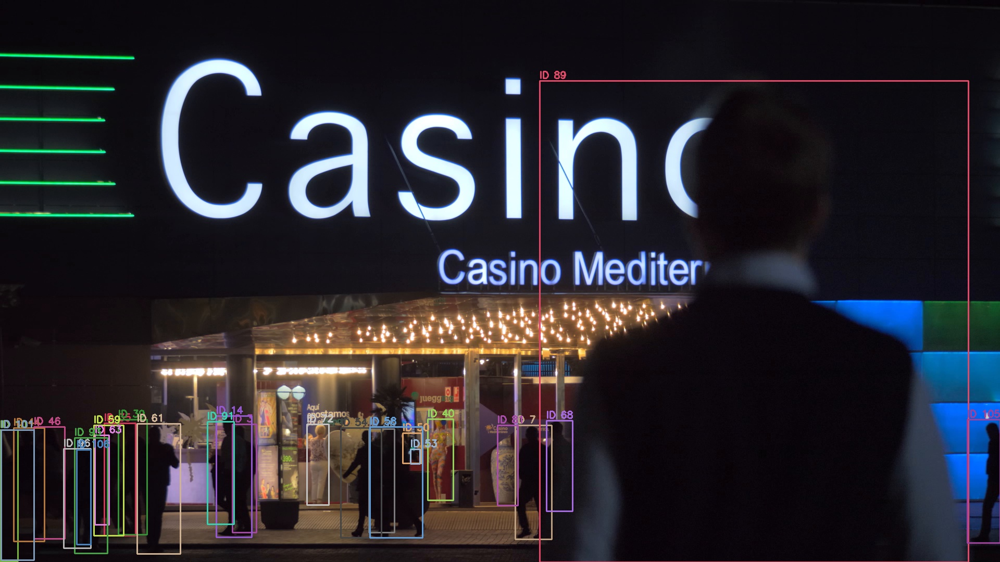

In [ ]:
STRIDE = 1
LOCAL_BASE = Path('/content/ml6_new_video') if IN_COLAB else lab.path('new_video_local')
release_key=tl.verify_release(RELEASE_DIR)['release_id'][:12]
LOCAL_OUT = LOCAL_BASE / f'{tl.file_hash(VIDEO_PATH)[:16]}_{release_key}_stride{STRIDE}'
video,metadata = tl.infer_video(RELEASE_DIR,VIDEO_PATH,LOCAL_OUT,stride=STRIDE)
display(pd.Series(metadata))
display(Video(str(video),embed=True,width=900))
display(Image(filename=str(LOCAL_OUT/'preview.jpg')))

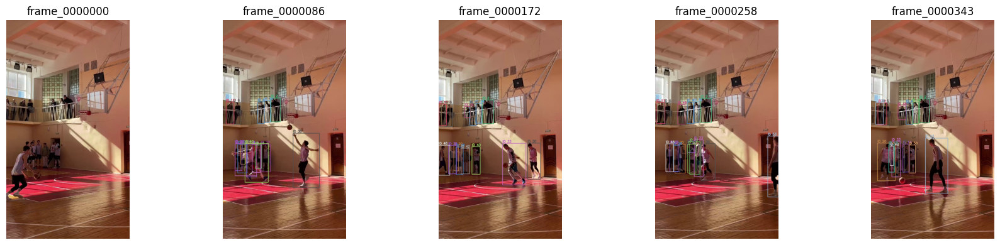

,Кадр,"Время, с",ID,x1,y1,x2,y2,Уверенность,Обработан сетью
0,1,0.016667,1,205.038467,718.145752,255.260193,863.901001,0.999877,True
1,1,0.016667,2,332.805420,437.851990,391.766998,575.646362,0.999941,True
2,1,0.016667,3,1.060393,730.094971,158.476822,1055.313354,0.999577,True
3,1,0.016667,4,256.867676,461.409363,295.570496,587.744934,0.999711,True
4,1,0.016667,5,240.170258,711.405090,313.841675,868.623779,0.997576,True
5,1,0.016667,6,109.780128,462.562683,155.561081,592.343140,0.997013,True
6,1,0.016667,7,0.005338,457.050720,29.545769,580.967957,0.996457,True
7,1,0.016667,8,164.621689,700.774902,207.746445,858.113037,0.998666,True
8,1,0.016667,9,110.797249,718.193481,168.315735,871.348450,0.505081,True
9,1,0.016667,10,25.660906,461.214111,67.628288,586.388062,0.991841,True


In [ ]:
fig,axes=plt.subplots(1,len(metadata['previews']),figsize=(18,4))
for ax,p in zip(np.atleast_1d(axes),metadata['previews']):
    ax.imshow(plt.imread(p)); ax.set_title(Path(p).stem); ax.axis('off')
plt.tight_layout(); plt.show()
display(pd.read_csv(LOCAL_OUT/'tracks.csv').head(20).rename(columns={
    'frame_idx':'Кадр','time_seconds':'Время, с','track_id':'ID','score':'Уверенность','processed':'Обработан сетью'}))

In [ ]:
# Отдельный каталог для каждого входного видео; никакие старые результаты не перезаписываются.
DEST=lab.path('inference')/f'{INPUT_STEM}_{metadata["source_sha256"][:12]}_stride{STRIDE}'
DEST.mkdir(parents=True,exist_ok=True)
for p in LOCAL_OUT.iterdir():
    if p.is_file():
        tl.shutil.copyfile(p,DEST/p.name)
        assert tl.file_hash(p)==tl.file_hash(DEST/p.name)
print('Сохранено на Drive:',DEST)
print('annotated_video.mp4 | preview.jpg | tracks.csv | tracks.json')

Сохранено на Drive: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2/inference/ТестДанк_9d42438b9808_stride1
annotated_video.mp4 | preview.jpg | tracks.csv | tracks.json
